In [9]:
import torch
import numpy as np
import cv2

from sift import SIFTParams, build_octaves, build_dog, read_octaves
from util import draw_octaves_grid, assert_octaves

In [10]:
# read the same way as in course to reuse numerical tests

image = cv2.imread("data/mysh1.jpg")

rows, cols = image.shape[:2]
image = cv2.resize(image, (cols // 8, rows // 8), interpolation=cv2.INTER_AREA)
image = cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
image = torch.from_numpy(image).to(torch.float32) / 255.0
image = image.unsqueeze(0)

# F.to_pil_image(image)

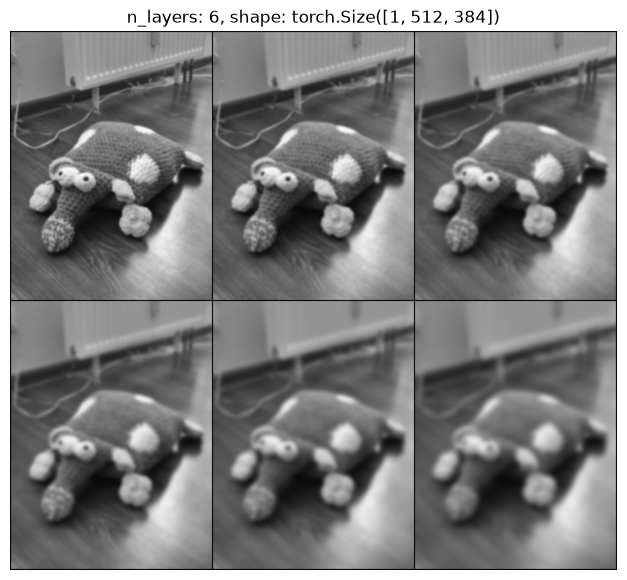

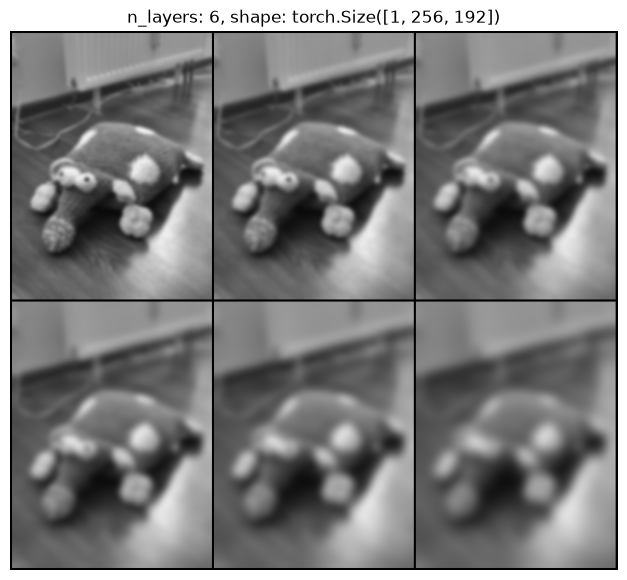

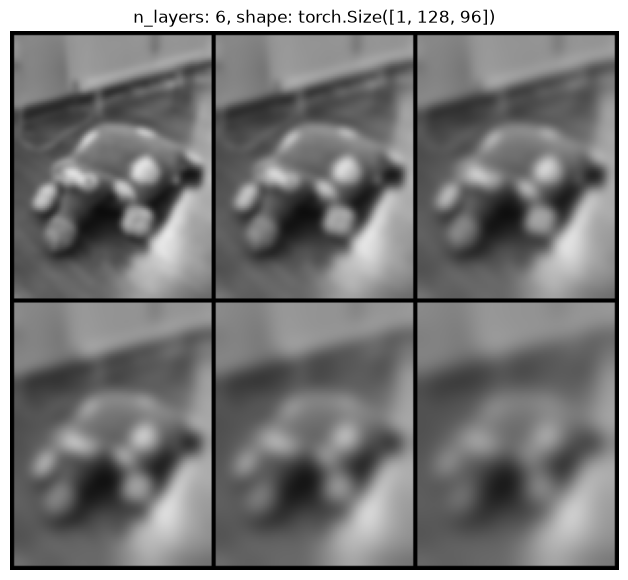

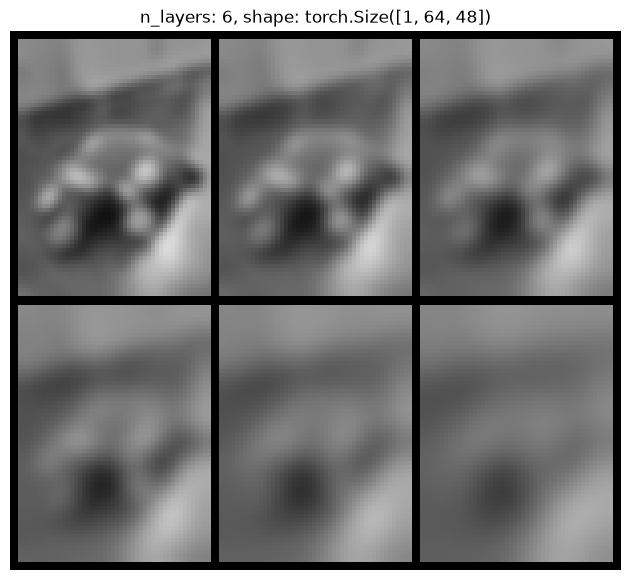

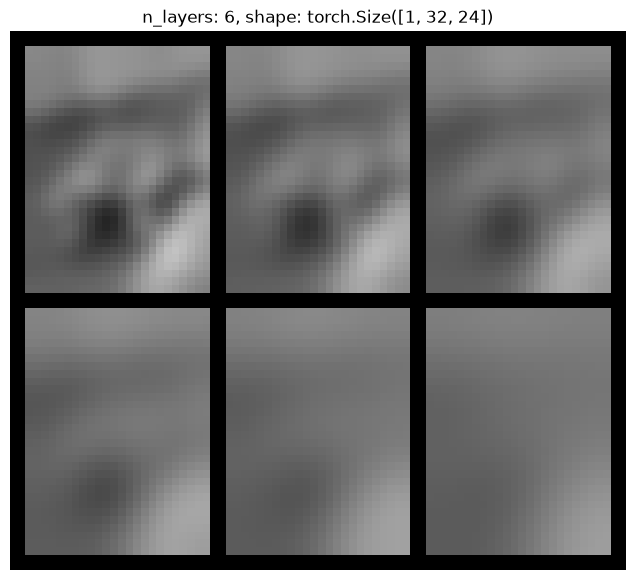

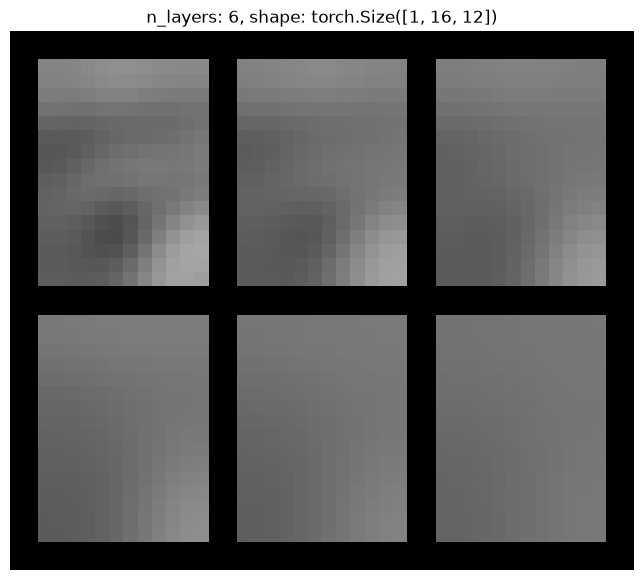

In [11]:
params = SIFTParams()
params.upscale_first = False

octaves = build_octaves(image, params)

draw_octaves_grid(octaves)

In [12]:
ref_octaves = read_octaves('data/test_steps_data/step1_octaves.yml.gz')

assert_octaves(octaves, ref_octaves)

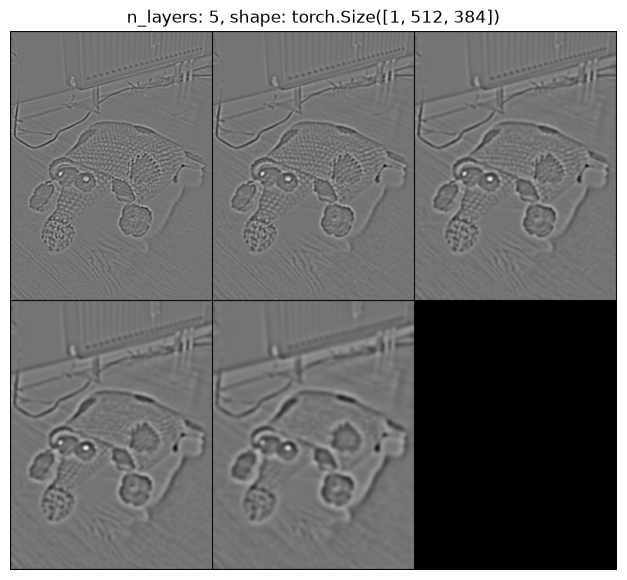

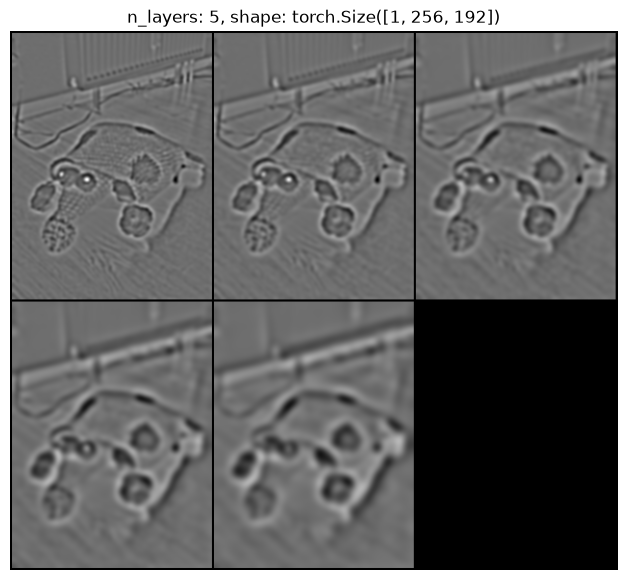

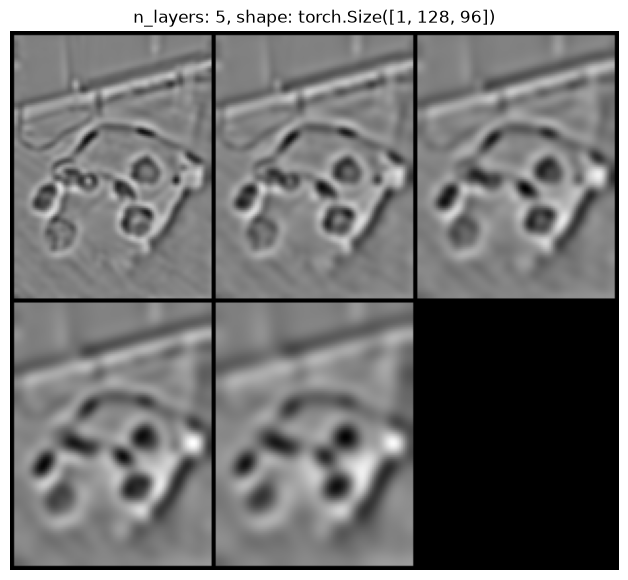

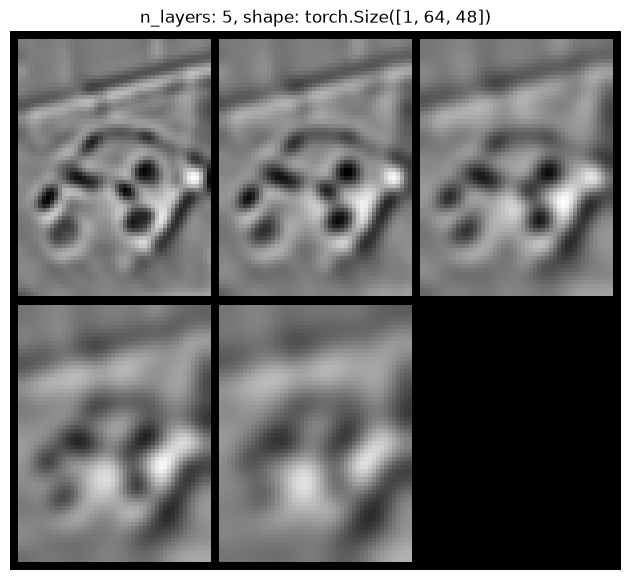

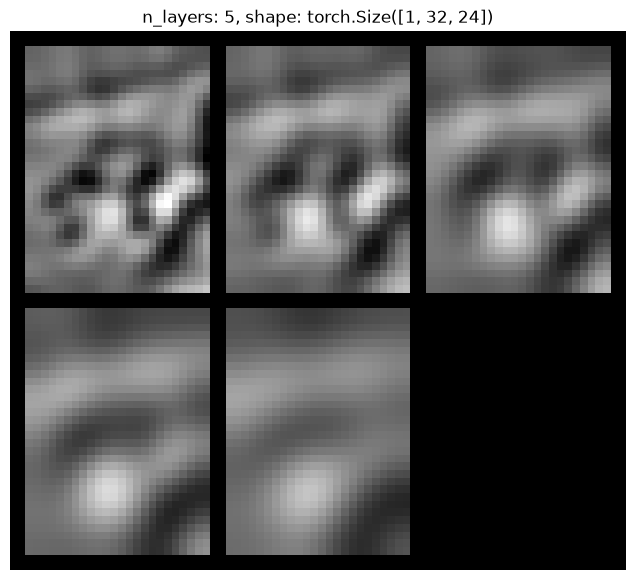

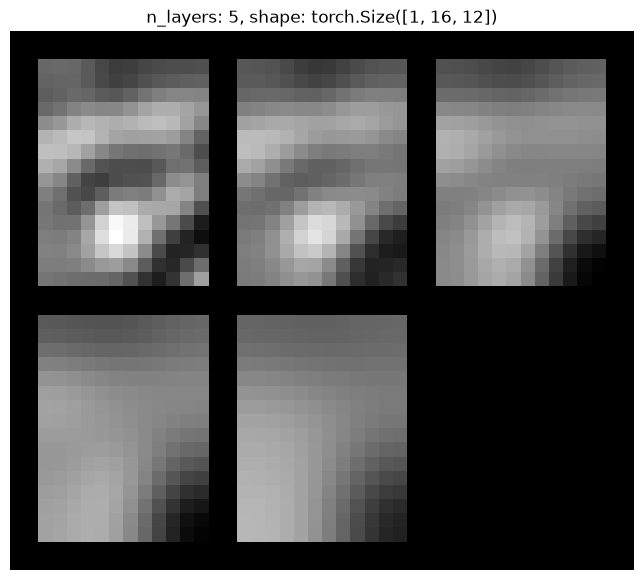

In [13]:
dog = build_dog(octaves)

draw_octaves_grid(dog, normalize=True)

In [14]:
ref_dog = read_octaves("data/test_steps_data/step2_dog.yml.gz")

assert_octaves(dog, ref_dog)